<a href="https://colab.research.google.com/github/Nanzz1112/UTS-AI/blob/main/klasifikasi_tingkat_stress.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
df = pd.read_csv('StressLevelDataset.csv')
print(df.isnull().sum())

anxiety_level                   0
self_esteem                     0
mental_health_history           0
depression                      0
headache                        0
blood_pressure                  0
sleep_quality                   0
breathing_problem               0
noise_level                     0
living_conditions               0
safety                          0
basic_needs                     0
academic_performance            0
study_load                      0
teacher_student_relationship    0
future_career_concerns          0
social_support                  0
peer_pressure                   0
extracurricular_activities      0
bullying                        0
stress_level                    0
dtype: int64


In [ ]:
print(df.duplicated().sum())

0


In [ ]:
print(df.describe().T)

                               count       mean       std  min   25%   50%  \
anxiety_level                 1100.0  11.063636  6.117558  0.0   6.0  11.0   
self_esteem                   1100.0  17.777273  8.944599  0.0  11.0  19.0   
mental_health_history         1100.0   0.492727  0.500175  0.0   0.0   0.0   
depression                    1100.0  12.555455  7.727008  0.0   6.0  12.0   
headache                      1100.0   2.508182  1.409356  0.0   1.0   3.0   
blood_pressure                1100.0   2.181818  0.833575  1.0   1.0   2.0   
sleep_quality                 1100.0   2.660000  1.548383  0.0   1.0   2.5   
breathing_problem             1100.0   2.753636  1.400713  0.0   2.0   3.0   
noise_level                   1100.0   2.649091  1.328127  0.0   2.0   3.0   
living_conditions             1100.0   2.518182  1.119208  0.0   2.0   2.0   
safety                        1100.0   2.737273  1.406171  0.0   2.0   2.0   
basic_needs                   1100.0   2.772727  1.433761  0.0  

In [ ]:
print(df.nunique())

anxiety_level                   22
self_esteem                     31
mental_health_history            2
depression                      28
headache                         6
blood_pressure                   3
sleep_quality                    6
breathing_problem                6
noise_level                      6
living_conditions                6
safety                           6
basic_needs                      6
academic_performance             6
study_load                       6
teacher_student_relationship     6
future_career_concerns           6
social_support                   4
peer_pressure                    6
extracurricular_activities       6
bullying                         6
stress_level                     3
dtype: int64


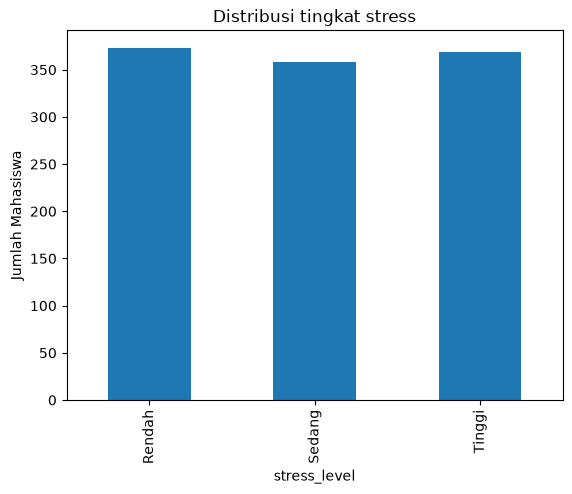

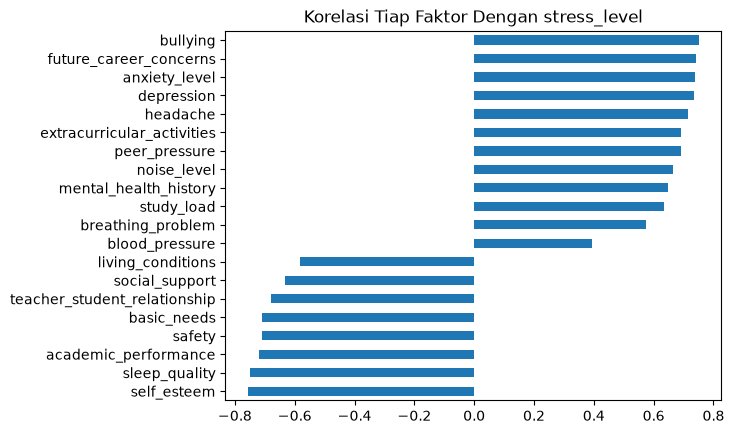

Data latih: (880, 20) | Data uji: (220, 20)

              anxiety_level  depression  self_esteem  bullying
stress_level                                                  
0                      5.43        6.01        25.25      1.25
1                     11.43       11.87        19.26      2.56
2                     16.40       19.83         8.78      4.05

Logistic Regression [0.9   0.886 0.873 0.859 0.886] Rata-Rata 0.8809
Akurasi: 0.8818
              precision    recall  f1-score   support

      Rendah       0.86      0.85      0.86        74
      Sedang       0.90      0.92      0.91        72
      Tinggi       0.88      0.88      0.88        74

    accuracy                           0.88       220
   macro avg       0.88      0.88      0.88       220
weighted avg       0.88      0.88      0.88       220



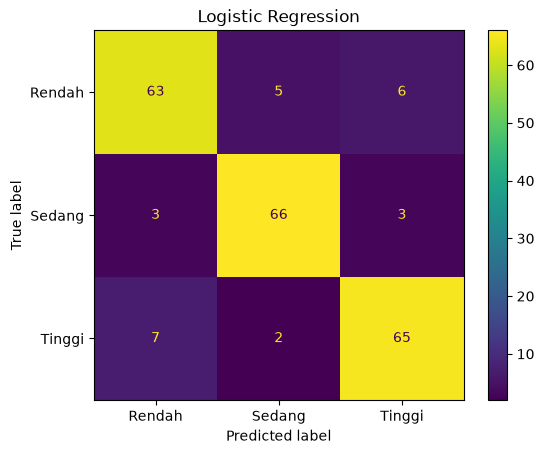

Akurasi data latih: 0.9068181818181819
Akurasi data uji  : 0.8818181818181818

--------------------------------------------------

Random Forest [0.9   0.882 0.868 0.845 0.891] Rata-Rata 0.8773
Akurasi: 0.8864
              precision    recall  f1-score   support

      Rendah       0.91      0.84      0.87        74
      Sedang       0.89      0.93      0.91        72
      Tinggi       0.86      0.89      0.87        74

    accuracy                           0.89       220
   macro avg       0.89      0.89      0.89       220
weighted avg       0.89      0.89      0.89       220



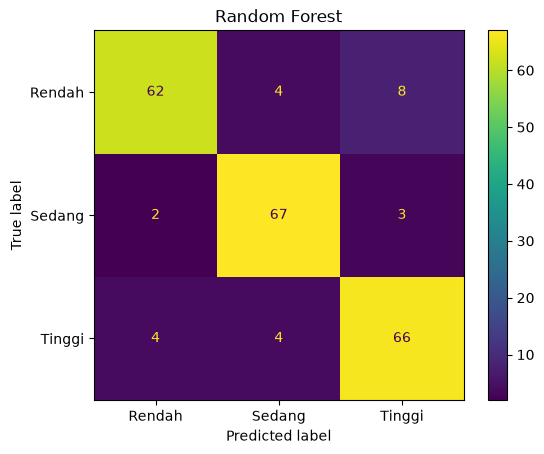

Akurasi data latih: 1.0
Akurasi data uji  : 0.8863636363636364

--------------------------------------------------



In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

df = pd.read_csv('StressLevelDataset.csv')
X = df.drop(columns=['stress_level'])
y = df['stress_level']

df['stress_level'].value_counts().sort_index().plot(kind='bar', title='Distribusi tingkat stress')
plt.xticks([0, 1, 2], ['Rendah', 'Sedang', 'Tinggi'])
plt.ylabel('Jumlah Mahasiswa')
plt.show()

df.corr()['stress_level'].drop('stress_level').sort_values().plot(kind='barh', title='Korelasi Tiap Faktor Dengan stress_level')
plt.show()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Data latih:', X_train.shape, '| Data uji:', X_test.shape)

models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
}

print()
print(df.groupby('stress_level')[['anxiety_level', 'depression', 'self_esteem', 'bullying']].mean().round(2))
print()

for name, model in models.items():
    s = cross_val_score(model, X, y, cv=5)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(name, s.round(3), 'Rata-Rata', s.mean().round(4))
    print('Akurasi:', round(accuracy_score(y_test, pred), 4))

    tingkat_stress = ['Rendah', 'Sedang', 'Tinggi']
    print(classification_report(y_test, pred, target_names=tingkat_stress))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=tingkat_stress)
    plt.title(name)
    plt.show()

    print('Akurasi data latih:', model.score(X_train, y_train))
    print('Akurasi data uji  :', model.score(X_test, y_test))
    print()
    print('-' * 50)
    print()

blood_pressure                  0.151
sleep_quality                   0.075
academic_performance            0.072
teacher_student_relationship    0.068
depression                      0.066
social_support                  0.057
basic_needs                     0.055
headache                        0.051
self_esteem                     0.051
bullying                        0.051
future_career_concerns          0.049
anxiety_level                   0.049
peer_pressure                   0.046
safety                          0.044
extracurricular_activities      0.041
living_conditions               0.021
noise_level                     0.018
study_load                      0.017
breathing_problem               0.012
mental_health_history           0.007
dtype: float64


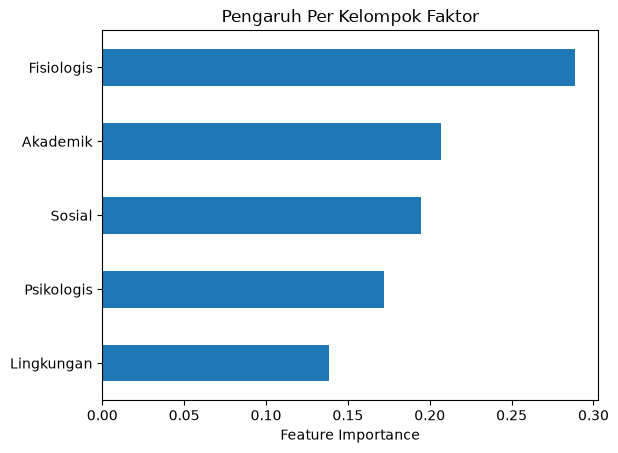

In [ ]:
rf = models['Random Forest']
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.round(3))

groups = {
    'Psikologis': ['anxiety_level', 'self_esteem', 'mental_health_history', 'depression'],
    'Fisiologis': ['headache', 'blood_pressure', 'sleep_quality', 'breathing_problem'],
    'Lingkungan': ['noise_level', 'living_conditions', 'safety', 'basic_needs'],
    'Akademik': ['academic_performance', 'study_load', 'teacher_student_relationship', 'future_career_concerns'],
    'Sosial': ['social_support', 'peer_pressure', 'extracurricular_activities', 'bullying'],
}

group_imp = pd.Series({g: imp[cols].sum() for g, cols in groups.items()}).sort_values()
group_imp.plot(kind='barh', title='Pengaruh Per Kelompok Faktor')
plt.xlabel('Feature Importance')
plt.show()